In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os,json,time
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV
import joblib

import warnings
warnings.filterwarnings('ignore')

In [ ]:
data = pd.read_csv('Dataset/Final Dataset.csv')
train_idx = pd.read_csv('Dataset/train_idx.csv').iloc[:,0].values
test_idx = pd.read_csv('Dataset/test_idx.csv').iloc[:,0].values
data = data.dropna()

In [ ]:
print(data['EnergyRating'].value_counts())

EnergyRating
A2    38480
B3    24977
C1    20371
C2    18330
B2    17996
C3    14914
B1    14500
A3    13889
D1    12867
D2    11196
A1     9675
E1     7247
E2     5618
Name: count, dtype: int64


In [ ]:
SEED = 25223721
DEVICE = "cuda"
for d in ["Figures", "Outputs", "Models"]:
    os.makedirs(d, exist_ok=True)

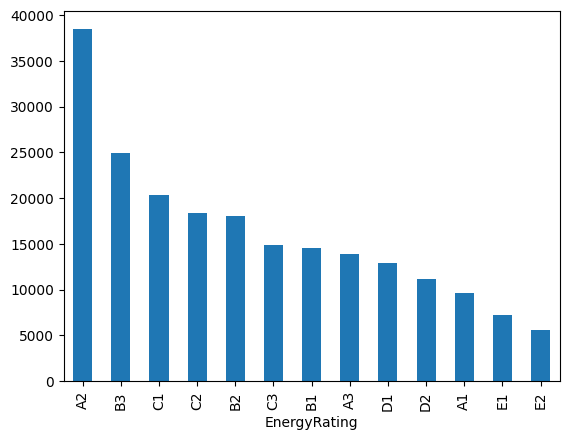

In [ ]:
data['EnergyRating'].value_counts().plot(kind='bar')
plt.show()

Features to keep and exclude

In [ ]:
TARGET = 'EnergyRating'
all_bands = ['AI','A2','A3', "B1", "B2", "B3", "C1", "C2", "C3", "D1", "D2", "E1", "E2", "F", "G"]
present = set(data[TARGET].dropna().astype(str).str.strip())
order = [b for b in all_bands if b in present]
band_to_int = {b:i for i,b in enumerate(order)}
y = data[TARGET].astype(str).str.strip().map(band_to_int)
X = data.drop(columns = ['BerRating','CO2Rating',TARGET]).copy()
cat_cols = X.select_dtypes(exclude = 'number').columns.tolist()
for c in cat_cols:
  X[c] = X[c].astype(str).str.strip().replace('NaN',np.nan).astype('category')

print('Categorical Columns handled are: ',cat_cols)

Categorical Columns handled are:  ['MainSpaceHeatingFuel', 'CountyName', 'DwellingTypeDescr', 'StructureType', 'PredominantRoofType', 'MainWaterHeatingFuel', 'VentilationMethod', 'DraftLobby', 'SuspendedWoodenFloor', 'InsulationType', 'SolarHotWaterHeating']


Splitting the data

In [ ]:
valid_train_idx = np.intersect1d(train_idx, X.index)
valid_test_idx = np.intersect1d(test_idx, X.index)

X_tr, X_te = X.loc[valid_train_idx], X.loc[valid_test_idx]
y_tr, y_te = y.loc[valid_train_idx], y.loc[valid_test_idx]

Class counts

In [ ]:
counts = pd.DataFrame(
    {
        'train': pd.Series(y_tr).value_counts().sort_index(),
        'test': pd.Series(y_te).value_counts().sort_index()
    }
)
counts.index = order
counts["train_%"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts["test_%"] = (counts["test"] / counts["test"].sum() * 100).round(1)
print(counts)

    train  test  train_%  test_%
A2  30797  7683     19.2    19.1
A3  11134  2755      6.9     6.9
B1  11599  2901      7.2     7.2
B2  14365  3631      9.0     9.0
B3  19984  4993     12.5    12.4
C1  16300  4071     10.2    10.1
C2  14620  3710      9.1     9.2
C3  11944  2970      7.5     7.4
D1  10276  2591      6.4     6.5
D2   8940  2256      5.6     5.6
E1   5808  1439      3.6     3.6
E2   4489  1129      2.8     2.8


In [ ]:
N_SAMPLE = 60000
# Remove any NaN values from y_tr and align X_tr accordingly
valid_mask = ~y_tr.isna()
X_tr = X_tr[valid_mask]
y_tr = y_tr[valid_mask].astype(int)

if N_SAMPLE < len(X_tr):
    S_idx, _ = train_test_split(np.arange(len(X_tr)), train_size=N_SAMPLE, stratify=y_tr, random_state=SEED)
else:
    S_idx = np.arange(len(X_tr))
XS, yS = X_tr.iloc[S_idx].reset_index(drop=True), y_tr.iloc[S_idx].values
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(XS, yS))
print("Tuning sample:", XS.shape)

def make_model(params, n_estimators=100, early_stop=None):
    return XGBClassifier(objective="multi:softprob", tree_method="hist", device=DEVICE,
                         enable_categorical=True, n_estimators=n_estimators,
                         early_stopping_rounds=early_stop, random_state=SEED, n_jobs=-1, **params)

def cv_score(params, use_w, n_estimators=100, early_stop=None):
    f1s, iters = [], []
    for tr_i, va_i in folds:
        Xa, Xb, ya, yb = XS.iloc[tr_i], XS.iloc[va_i], yS[tr_i], yS[va_i]
        kw = {"sample_weight": compute_sample_weight("balanced", ya) if use_w else None}
        if early_stop:
            kw.update(eval_set=[(Xb, yb)], verbose=False)
            if use_w:
                kw["sample_weight_eval_set"] = [compute_sample_weight("balanced", yb)]
        m = make_model(params, n_estimators, early_stop).fit(Xa, ya, **kw)
        f1s.append(f1_score(yb, m.predict(Xb), average="macro"))
        if early_stop:
            iters.append(m.best_iteration + 1)
    return np.mean(f1s), np.std(f1s), (int(np.mean(iters)) if iters else n_estimators)

base_cv = {}
for use_w in [False, True]:
    mu, sd, _ = cv_score({}, use_w)
    base_cv[use_w] = mu
    print(f"Default XGBoost, class weights = {use_w}: CV macro-F1 = {mu:.3f} +/- {sd:.3f}")
USE_W = base_cv[True] > base_cv[False]
print("Class weights will be used:", USE_W)

Tuning sample: (60000, 40)
Default XGBoost, class weights = False: CV macro-F1 = 0.513 +/- 0.002
Default XGBoost, class weights = True: CV macro-F1 = 0.513 +/- 0.005
Class weights will be used: False


Choosing the best parameters

In [ ]:
N_ITER = 5
param_dist = {"n_estimators": randint(100, 500), "learning_rate": loguniform(0.03, 0.3),
              "max_depth": randint(3, 11), "min_child_weight": loguniform(1, 20),
              "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
              "gamma": uniform(0, 5), "reg_alpha": loguniform(1e-3, 10), "reg_lambda": loguniform(0.5, 20)}

search = RandomizedSearchCV(make_model({}), param_distributions=param_dist, n_iter=N_ITER,
                            scoring="f1_macro", cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                            random_state=SEED, n_jobs=1, refit=False, verbose=2)
fit_kw = {"sample_weight": compute_sample_weight("balanced", yS)} if USE_W else {}
search.fit(XS, yS, **fit_kw)

res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
res.to_csv("Outputs/xgb_search_results.csv", index=False)
best_params = {k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in search.best_params_.items()}
n_trees = int(best_params.pop("n_estimators"))
print(f"Best CV macro-F1: {search.best_score_:.4f} +/- {res.iloc[0]['std_test_score']:.4f}")
print("Best parameters:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()}, "| trees:", n_trees)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END colsample_bytree=0.9036678958167479, gamma=3.6276562012697084, learning_rate=0.07054792363968546, max_depth=4, min_child_weight=1.6707705882838741, n_estimators=292, reg_alpha=2.318947463897659, reg_lambda=8.59086620001354, subsample=0.6604373037579956; total time=   7.2s
[CV] END colsample_bytree=0.9036678958167479, gamma=3.6276562012697084, learning_rate=0.07054792363968546, max_depth=4, min_child_weight=1.6707705882838741, n_estimators=292, reg_alpha=2.318947463897659, reg_lambda=8.59086620001354, subsample=0.6604373037579956; total time=   7.5s
[CV] END colsample_bytree=0.9036678958167479, gamma=3.6276562012697084, learning_rate=0.07054792363968546, max_depth=4, min_child_weight=1.6707705882838741, n_estimators=292, reg_alpha=2.318947463897659, reg_lambda=8.59086620001354, subsample=0.6604373037579956; total time=   7.5s
[CV] END colsample_bytree=0.9036678958167479, gamma=3.6276562012697084, learning_rate=0.070547

Fitting the Model on trai ing data with best parameters

In [ ]:
w_all = compute_sample_weight("balanced", y_tr) if USE_W else None
final = make_model(best_params, n_trees).fit(X_tr, y_tr, sample_weight=w_all)
base = make_model({}, 100).fit(X_tr, y_tr, sample_weight=w_all)
pred_tr, pred_te, pred_base = final.predict(X_tr), final.predict(X_te), base.predict(X_te)

                                   accuracy  macro_F1  weighted_F1  \
XGBoost untuned (baseline) - test     0.611     0.556        0.609   
XGBoost tuned - test                  0.616     0.560        0.614   
XGBoost tuned - train                 0.854     0.853        0.854   

                                   within_1_band  
XGBoost untuned (baseline) - test          0.944  
XGBoost tuned - test                       0.947  
XGBoost tuned - train                      0.974  
Macro-F1 -> CV (tuning sample): 0.515 | train: 0.853 | test: 0.560
              precision    recall  f1-score   support

          A2      0.957     0.957     0.957      7683
          A3      0.728     0.704     0.715      2755
          B1      0.613     0.653     0.632      2901
          B2      0.583     0.545     0.563      3631
          B3      0.569     0.681     0.620      4993
          C1      0.499     0.436     0.466      4071
          C2      0.468     0.475     0.472      3710
          C3   

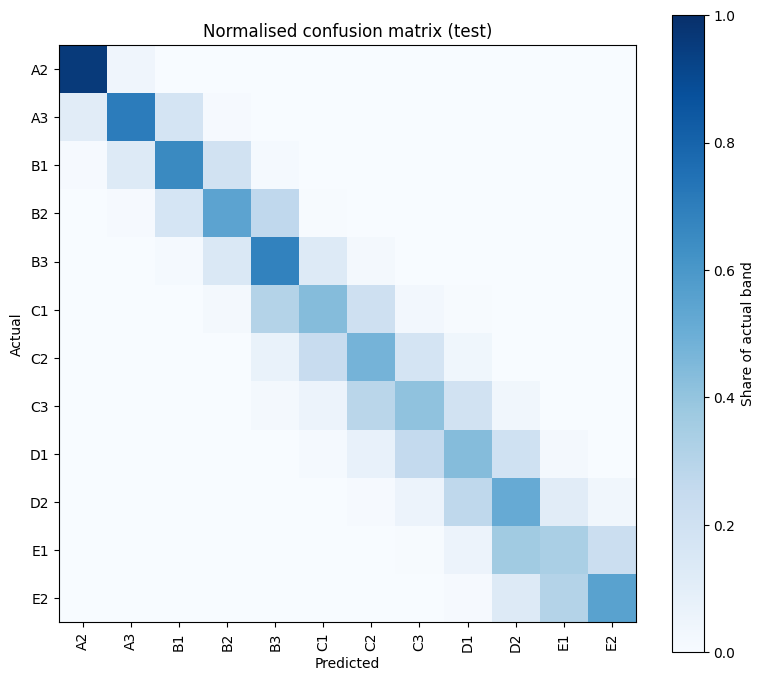

In [ ]:
# Clean y_te and X_te of NaN values prior to calculating metrics
valid_test_mask = ~y_te.isna()
X_te_clean = X_te[valid_test_mask]
y_te_clean = y_te[valid_test_mask].astype(int)

# Adjust predictions matching the non-NaN test indices
pred_te_clean = pred_te[valid_test_mask]
pred_base_clean = pred_base[valid_test_mask]

def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_F1": f1_score(y_true, y_pred, average="macro"),
            "weighted_F1": f1_score(y_true, y_pred, average="weighted"),
            "within_1_band": float((np.abs(y_true - y_pred) <= 1).mean())}

comp = pd.DataFrame({"XGBoost untuned (baseline) - test": metrics(y_te_clean, pred_base_clean),
                     "XGBoost tuned - test": metrics(y_te_clean, pred_te_clean),
                     "XGBoost tuned - train": metrics(y_tr, pred_tr)}).T.round(3)
print(comp)
comp.to_csv("Outputs/xgb_test_metrics.csv")
print(f"Macro-F1 -> CV (tuning sample): {search.best_score_:.3f} | train: {comp.iloc[2]['macro_F1']:.3f} | test: {comp.iloc[1]['macro_F1']:.3f}")
print(classification_report(y_te_clean, pred_te_clean, target_names=order, digits=3))

cm = confusion_matrix(y_te_clean, pred_te_clean, normalize="true")
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(order)), order, rotation=90); plt.yticks(range(len(order)), order)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.colorbar(label="Share of actual band")
plt.title("Normalised confusion matrix (test)")
plt.tight_layout(); plt.savefig("Figures/xgb_confusion_matrix.png", dpi=200); plt.show()

Error Analysis

In [ ]:
err, diff = pred_te_clean != y_te_clean, np.abs(pred_te_clean - y_te_clean)
print(f"Errors: {err.mean():.1%} of test rows. Of those errors: "
      f"{(diff[err] == 1).mean():.1%} are one band off, {(diff[err] >= 2).mean():.1%} are two or more bands off")

te = data.loc[y_te_clean.index].copy()
te["era"] = pd.cut(te["Year_of_Construction"], [0, 1950, 1970, 1980, 1990, 2000, 2010, 2100]).astype(str)
era = te["era"].values
era_tbl = pd.DataFrame({"n": pd.Series(era).value_counts().sort_index()})

era_tbl["accuracy"] = [(pred_te_clean[era == e] == y_te_clean[era == e]).mean() for e in era_tbl.index]
era_tbl["within_1_band"] = [(diff[era == e] <= 1).mean() for e in era_tbl.index]
era_tbl["macro_F1"] = [f1_score(y_te_clean[era == e], pred_te_clean[era == e], average="macro") for e in era_tbl.index]
print(era_tbl.round(3))
era_tbl.to_csv("Outputs/xgb_error_by_era.csv")

Errors: 38.4% of test rows. Of those errors: 86.1% are one band off, 13.9% are two or more bands off
                 n  accuracy  within_1_band  macro_F1
(0, 1950]     5036     0.468          0.882     0.494
(1950, 1970]  3694     0.505          0.920     0.540
(1970, 1980]  4779     0.508          0.929     0.543
(1980, 1990]  3388     0.520          0.938     0.526
(1990, 2000]  5813     0.555          0.950     0.518
(2000, 2010]  9518     0.600          0.961     0.522
(2010, 2100]  7901     0.932          0.995     0.330


Feature Importance

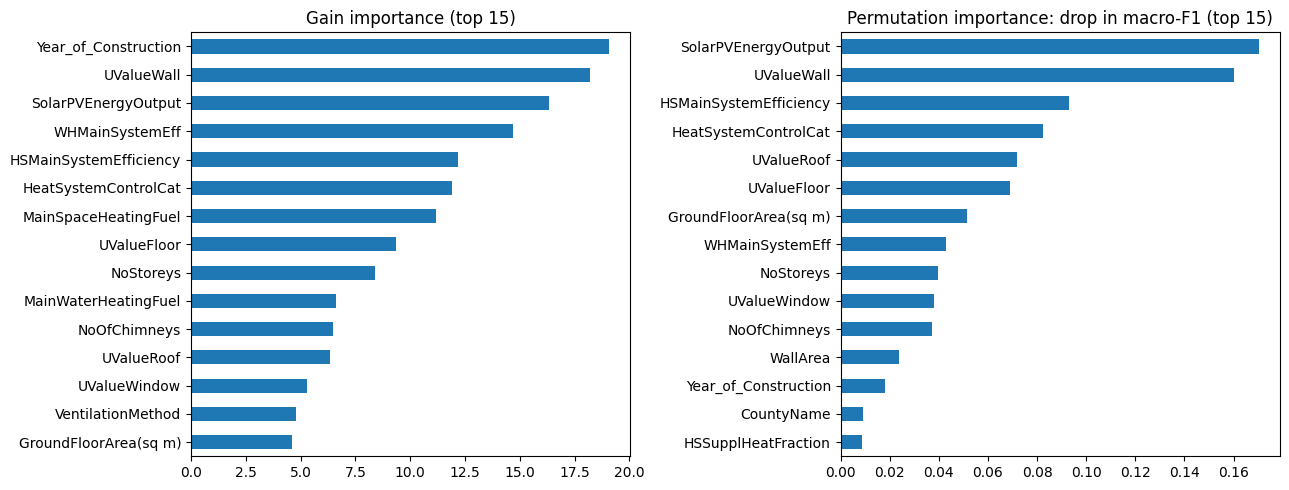

In [ ]:
gain = pd.Series(final.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
rs = np.random.default_rng(SEED)
samp = rs.choice(len(X_te_clean), min(15000, len(X_te_clean)), replace=False)
Xp, yp = X_te_clean.iloc[samp].reset_index(drop=True), y_te_clean.iloc[samp].values
base_f1 = f1_score(yp, final.predict(X_te_clean.iloc[samp]), average="macro")
perm = {}
for c in Xp.columns:
    drops = []
    for r in range(3):
        Xs = Xp.copy()
        Xs[c] = Xs[c].sample(frac=1, random_state=SEED + r).values
        drops.append(base_f1 - f1_score(yp, final.predict(Xs), average="macro"))
    perm[c] = np.mean(drops)
perm = pd.Series(perm).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
gain.head(15).sort_values().plot.barh(ax=ax[0], title="Gain importance (top 15)")
perm.head(15).sort_values().plot.barh(ax=ax[1], title="Permutation importance: drop in macro-F1 (top 15)")
plt.tight_layout(); plt.savefig("Figures/xgb_importance.png", dpi=200); plt.show()
pd.DataFrame({"gain": gain, "permutation": perm}).to_csv("Outputs/xgb_feature_importance.csv")

Saving the model

In [ ]:
final.save_model("Models/xgb_energyrating.json")
with open("Outputs/xgb_best_params.json", "w") as f:
    json.dump({"params": best_params, "n_estimators": int(n_trees * 1.1), "class_weights": bool(USE_W),
               "bands": order}, f, indent=2)